# MEMC cvičení 0 – Opakování pravděpodobnosti a statistiky

---

Tento sešit je **příprava před kurzem**. Projdeme jen to, co budeme v dalších cvičeních používat pořád dokola:

- náhodná veličina, střední hodnota a rozptyl
- základní rozdělení (rovnoměrné, normální, exponenciální, Bernoulliho, binomické, Poissonovo)
- zákon velkých čísel
- **Čebyševova nerovnost**
- **centrální limitní věta (CLV)**
- jak z toho vyrobit interval spolehlivosti pro Monte Carlo odhad

Důraz je na **praxi**: u každého pojmu uvidíte krátké vysvětlení, kód a graf. Stačí vám standardní knihovny `random` a `math` a `matplotlib` pro grafy.

> Cíl: po tomto sešitu byste měli vědět, proč Monte Carlo odhad konverguje a jak velkou chybu s ním děláme.

In [1]:
import math
import random

import matplotlib.pyplot as plt

random.seed(1)  # opakovatelné výsledky


def samples(sampler, n):
    '''n volání generátoru -> seznam vzorků.'''
    return [sampler() for _ in range(n)]


def estimate(xs):
    '''Průměr a jeho směrodatná chyba s / sqrt(n) z hotového seznamu vzorků.'''
    n = len(xs)
    mean = sum(xs) / n
    var = sum((x - mean) ** 2 for x in xs) / (n - 1)  # výběrový rozptyl
    return mean, math.sqrt(var / n)


def Phi(x):
    '''Distribuční funkce N(0, 1) pomocí chybové funkce erf.'''
    return 0.5 * (1 + math.erf(x / math.sqrt(2)))

## 1. Náhodná veličina a generátor

**Náhodná veličina** $X$ je číslo, jehož hodnota závisí na náhodě. Popisuje ji rozdělení:

| Typ | Popis | Příklad |
|-----|-------|---------|
| Diskrétní | hodnoty $x_k$ s pravděpodobnostmi $p_k$ | hod kostkou |
| Spojitá | hustota $f(x)$, $P(a \le X \le b) = \int_a^b f(x)\,dx$ | doba čekání na tramvaj |

Distribuční funkce $F(x) = P(X \le x)$ existuje u obou typů.

**Pro počítač** je základ jediný generátor: `random.random()` vrací číslo z rovnoměrného rozdělení na $[0, 1)$. Všechno ostatní v kurzu z něj budeme **vyrábět**.

> Počítač generuje *pseudonáhodná* čísla – deterministický algoritmus, který se tváří náhodně. Se stejným `seed` dostanete stejnou posloupnost, což se hodí pro ladění.

[0.1344, 0.8474, 0.7638, 0.2551, 0.4954]


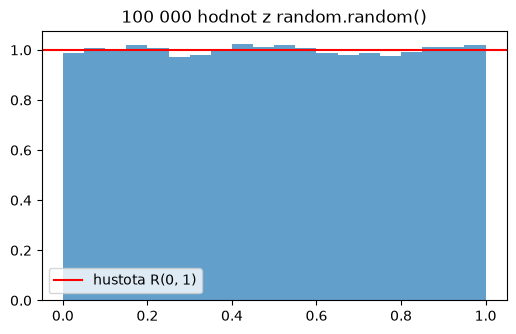

In [2]:
print([round(random.random(), 4) for _ in range(5)])

xs = samples(random.random, 100_000)
plt.figure(figsize=(6, 3.5))
plt.hist(xs, bins=20, range=(0, 1), density=True, alpha=0.7)
plt.axhline(1.0, color="red", label="hustota R(0, 1)")
plt.title("100 000 hodnot z random.random()")
plt.legend()
plt.show()

## 2. Střední hodnota a rozptyl

| | Diskrétní | Spojitá |
|---|-----------|---------|
| Střední hodnota $E X$ | $\sum_k x_k p_k$ | $\int x f(x)\,dx$ |
| Rozptyl $D X$ | $\sum_k (x_k - E X)^2 p_k$ | $\int (x - E X)^2 f(x)\,dx$ |

Směrodatná odchylka je $\sigma = \sqrt{D X}$. Pravidla, která budeme používat:

- $E(aX + b) = a\,E X + b$ a $E(X + Y) = E X + E Y$ (vždy)
- $D(aX + b) = a^2 D X$
- $D(X + Y) = D X + D Y$ (**pouze pro nezávislé** $X, Y$)
- $D X = E X^2 - (E X)^2$

### Monte Carlo v jedné větě

Střední hodnotu neznáme? Nasimulujeme $N$ nezávislých kopií $X_1, \dots, X_N$ a spočítáme průměr

$$\bar X_N = \frac{1}{N}\sum_{i=1}^N X_i \approx E X.$$

Rozptyl průměru je $D\bar X_N = \sigma^2 / N$, takže **směrodatná chyba** je $\sigma/\sqrt{N}$.

### Příklad: hod kostkou

In [3]:
hodnoty = [1, 2, 3, 4, 5, 6]
p = [1 / 6] * 6

EX = sum(x * q for x, q in zip(hodnoty, p))
VarX = sum((x - EX) ** 2 * q for x, q in zip(hodnoty, p))
print(f"přesně:   E X = {EX:.4f},  Var X = {VarX:.4f}  (= 35/12 = {35/12:.4f})")

xs = samples(lambda: random.randint(1, 6), 100_000)
m, se = estimate(xs)
print(f"simulace: E X = {m:.4f} +- {se:.4f}")
print(f"odchylka od přesné hodnoty: {m - EX:+.4f}  (to je {abs(m - EX) / se:.1f} směrodatné chyby)")

přesně:   E X = 3.5000,  Var X = 2.9167  (= 35/12 = 2.9167)
simulace: E X = 3.4960 +- 0.0054
odchylka od přesné hodnoty: -0.0040  (to je 0.7 směrodatné chyby)


Odchylka je typicky do **dvou** směrodatných chyb. Proč právě tolik, vysvětlí CLV níže.

## 3. Základní rozdělení

| Rozdělení | Parametry | $E X$ | $D X$ | Použití |
|-----------|-----------|-------|------------------------|---------|
| Bernoulliho | $p$ | $p$ | $p(1-p)$ | ano/ne (nastal požadavek?) |
| Binomické | $n, p$ | $np$ | $np(1-p)$ | počet úspěchů z $n$ pokusů |
| Poissonovo | $\lambda$ | $\lambda$ | $\lambda$ | počet událostí za dobu |
| Rovnoměrné | $a, b$ | $(a+b)/2$ | $(b-a)^2/12$ | základ všeho |
| Exponenciální | $\lambda$ | $1/\lambda$ | $1/\lambda^2$ | doba do události |
| Normální | $\mu, \sigma^2$ | $\mu$ | $\sigma^2$ | součty a průměry (CLV) |

Níže si ověříme tabulku simulací. Generátory bereme ze standardní knihovny; ty „vyrobíme sami" až v dalších cvičeních (diskrétní: cvičení 3, spojitá: cvičení 4).

In [4]:
def bernoulli(p):
    return 1 if random.random() < p else 0


def binomial(n, p):
    return sum(bernoulli(p) for _ in range(n))


zdroje = [
    # název, generátor, přesné E, přesné Var
    ("Bernoulli(0.3)",   lambda: bernoulli(0.3),            0.3,       0.3 * 0.7),
    ("Binomické(10, 0.3)", lambda: binomial(10, 0.3),       3.0,       10 * 0.3 * 0.7),
    ("Rovnoměrné(2, 5)", lambda: random.uniform(2, 5),      3.5,       9 / 12),
    ("Exponenciální(2)", lambda: random.expovariate(2.0),   0.5,       0.25),
    ("Normální(1, 2)",   lambda: random.gauss(1.0, 2.0),    1.0,       4.0),
]

print(f"{'rozdělení':22s} {'E (sim)':>10s} {'E (přesně)':>11s} {'Var (sim)':>10s} {'Var (přesně)':>13s}")
for nazev, gen, E, V in zdroje:
    xs = samples(gen, 100_000)
    m = sum(xs) / len(xs)
    v = sum((x - m) ** 2 for x in xs) / (len(xs) - 1)
    print(f"{nazev:22s} {m:10.4f} {E:11.4f} {v:10.4f} {V:13.4f}")

rozdělení                 E (sim)  E (přesně)  Var (sim)  Var (přesně)
Bernoulli(0.3)             0.3016      0.3000     0.2106        0.2100


Binomické(10, 0.3)         3.0006      3.0000     2.0929        2.1000
Rovnoměrné(2, 5)           3.4972      3.5000     0.7515        0.7500
Exponenciální(2)           0.5001      0.5000     0.2488        0.2500
Normální(1, 2)             1.0008      1.0000     3.9949        4.0000


### Poissonovo rozdělení z definice

Poissonovo rozdělení má $P(X = k) = \dfrac{\lambda^k e^{-\lambda}}{k!}$. Standardní knihovna ho nemá, ale střední hodnotu a rozptyl můžeme spočítat **přímo z definice** součtem (sumu zkrátíme, chvost je zanedbatelný):

In [5]:
lam = 4.0
pmf = [lam ** k * math.exp(-lam) / math.factorial(k) for k in range(60)]

EX = sum(k * q for k, q in enumerate(pmf))
VarX = sum((k - EX) ** 2 * q for k, q in enumerate(pmf))
print(f"sum p_k = {sum(pmf):.6f},  E X = {EX:.6f},  Var X = {VarX:.6f}   (obojí má být lambda = {lam})")

sum p_k = 1.000000,  E X = 4.000000,  Var X = 4.000000   (obojí má být lambda = 4.0)


### Jak vypadají hustoty a pravděpodobnostní funkce

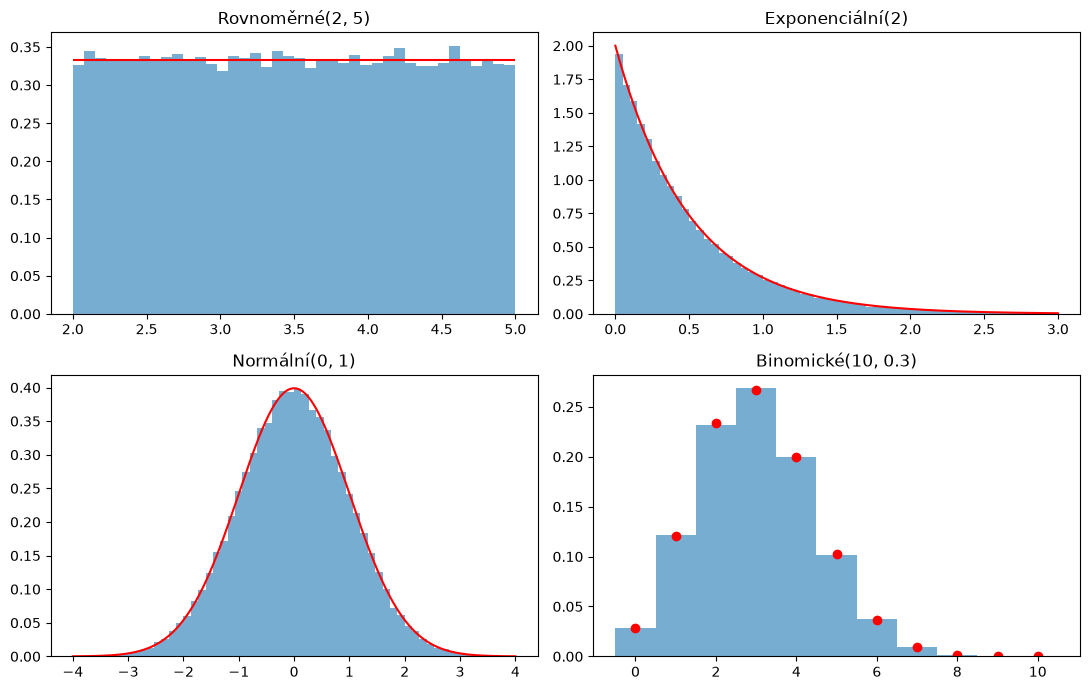

In [6]:
n = 100_000
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# rovnoměrné
xs = samples(lambda: random.uniform(2, 5), n)
ax = axes[0][0]
ax.hist(xs, bins=40, density=True, alpha=0.6)
ax.hlines(1 / 3, 2, 5, color="red")
ax.set_title("Rovnoměrné(2, 5)")

# exponenciální
xs = samples(lambda: random.expovariate(2.0), n)
ax = axes[0][1]
ax.hist(xs, bins=60, range=(0, 3), density=True, alpha=0.6)
grid = [i / 100 for i in range(301)]
ax.plot(grid, [2 * math.exp(-2 * x) for x in grid], "r")
ax.set_title("Exponenciální(2)")

# normální
xs = samples(lambda: random.gauss(0, 1), n)
ax = axes[1][0]
ax.hist(xs, bins=60, range=(-4, 4), density=True, alpha=0.6)
grid = [i / 50 - 4 for i in range(401)]
ax.plot(grid, [math.exp(-x * x / 2) / math.sqrt(2 * math.pi) for x in grid], "r")
ax.set_title("Normální(0, 1)")

# binomické
xs = samples(lambda: binomial(10, 0.3), n)
ax = axes[1][1]
ax.hist(xs, bins=[k - 0.5 for k in range(12)], density=True, alpha=0.6)
ax.plot(range(11), [math.comb(10, k) * 0.3 ** k * 0.7 ** (10 - k) for k in range(11)], "ro")
ax.set_title("Binomické(10, 0.3)")

plt.tight_layout()
plt.show()

Modře je histogram ze simulace, červeně přesná hustota (resp. pravděpodobnostní funkce). Shodují se, takže generátory fungují.

## 4. Zákon velkých čísel

> **Zákon velkých čísel (ZVČ):** pro nezávislé $X_i$ se stejnou střední hodnotou $\mu$ platí $\bar X_N \to \mu$ při $N \to \infty$.

Je to důvod, proč Monte Carlo *vůbec* funguje. Podívejme se na průběžný průměr hodů kostkou v pěti nezávislých pokusech:

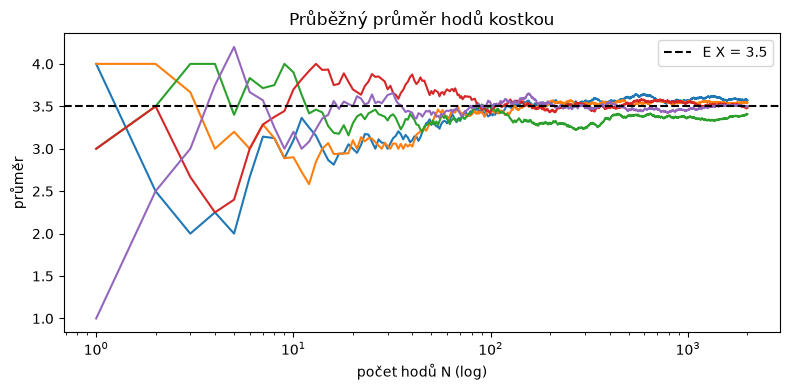

In [7]:
plt.figure(figsize=(8, 4))
for _ in range(5):
    s = 0
    prubeh = []
    for i in range(1, 2001):
        s += random.randint(1, 6)
        prubeh.append(s / i)
    plt.plot(range(1, 2001), prubeh)

plt.axhline(3.5, color="black", linestyle="--", label="E X = 3.5")
plt.xscale("log")
plt.xlabel("počet hodů N (log)")
plt.ylabel("průměr")
plt.title("Průběžný průměr hodů kostkou")
plt.legend()
plt.tight_layout()
plt.show()

Všech pět křivek se usadí u $3.5$. ZVČ ale říká jen **že** průměr konverguje, ne **jak rychle** ani **jak velkou chybu** máme po $N$ krocích. K tomu potřebujeme dva nástroje: Čebyševovu nerovnost a CLV.

## 5. Čebyševova nerovnost

Pro **libovolné** rozdělení s konečným rozptylem a každé $k > 0$ platí

$$P\big(|X - \mu| \ge k\sigma\big) \le \frac{1}{k^2}.$$

Pro průměr $\bar X_N$ (který má rozptyl $\sigma^2/N$) a toleranci $\delta$:

$$P\big(|\bar X_N - \mu| \ge \delta\big) \le \frac{\sigma^2}{N\delta^2}.$$

**Silná stránka:** platí vždy, nic nepředpokládáme o tvaru rozdělení.
**Slabá stránka:** je velmi **konzervativní** (odhad na horní mez je často hrubě nadsazený).

Porovnejme skutečné pravděpodobnosti s mezí $1/k^2$:

In [8]:
def cebysev_tabulka(nazev, gen, mu, sigma, n=200_000, normalni=False):
    xs = samples(gen, n)
    print(nazev)
    print(f"  {'k':>4s} {'skutečnost':>12s} {'Čebyšev <=':>12s}" + (f" {'normální (přesně)':>18s}" if normalni else ""))
    for k in (1.5, 2, 3, 4):
        emp = sum(abs(x - mu) >= k * sigma for x in xs) / n
        radek = f"  {k:4.1f} {emp:12.4f} {1 / k ** 2:12.4f}"
        if normalni:
            radek += f" {2 * (1 - Phi(k)):18.4f}"
        print(radek)
    print()


cebysev_tabulka("Rovnoměrné(0, 1)", random.random, 0.5, math.sqrt(1 / 12))
cebysev_tabulka("Exponenciální(1)", lambda: random.expovariate(1.0), 1.0, 1.0)
cebysev_tabulka("Normální(0, 1)", lambda: random.gauss(0, 1), 0.0, 1.0, normalni=True)

Rovnoměrné(0, 1)
     k   skutečnost   Čebyšev <=
   1.5       0.1345       0.4444
   2.0       0.0000       0.2500
   3.0       0.0000       0.1111
   4.0       0.0000       0.0625

Exponenciální(1)
     k   skutečnost   Čebyšev <=
   1.5       0.0812       0.4444
   2.0       0.0490       0.2500
   3.0       0.0178       0.1111
   4.0       0.0067       0.0625

Normální(0, 1)
     k   skutečnost   Čebyšev <=  normální (přesně)
   1.5       0.1330       0.4444             0.1336
   2.0       0.0455       0.2500             0.0455
   3.0       0.0028       0.1111             0.0027
   4.0       0.0001       0.0625             0.0001



Meze jsou vždy splněné, ale u normálního rozdělení je skutečnost pro $k = 3$ zhruba $0.003$, zatímco Čebyšev slibuje jen $\le 0.111$. To je cena za obecnost.

> Čebyševova nerovnost vyžaduje **konečný rozptyl**. U Cauchyho rozdělení rozptyl neexistuje (a dokonce ani střední hodnota), takže nerovnost ani ZVČ neplatí. Uvidíme ve cvičení 4.

## 6. Centrální limitní věta (CLV)

> **CLV:** nechť $X_i$ jsou nezávislé se stejným rozdělením, střední hodnotou $\mu$ a rozptylem $\sigma^2 \in (0, \infty)$. Pak standardizovaný průměr
> $$Z_N = \frac{\bar X_N - \mu}{\sigma/\sqrt{N}}$$
> konverguje v distribuci k $N(0, 1)$.

Jinými slovy: **ať je původní rozdělení jakékoli**, průměr mnoha kopií vypadá jako zvon. Podívejme se na to. Řádky jsou dvě velmi různá rozdělení (symetrické a silně zešikmené), sloupce rostoucí $N$:

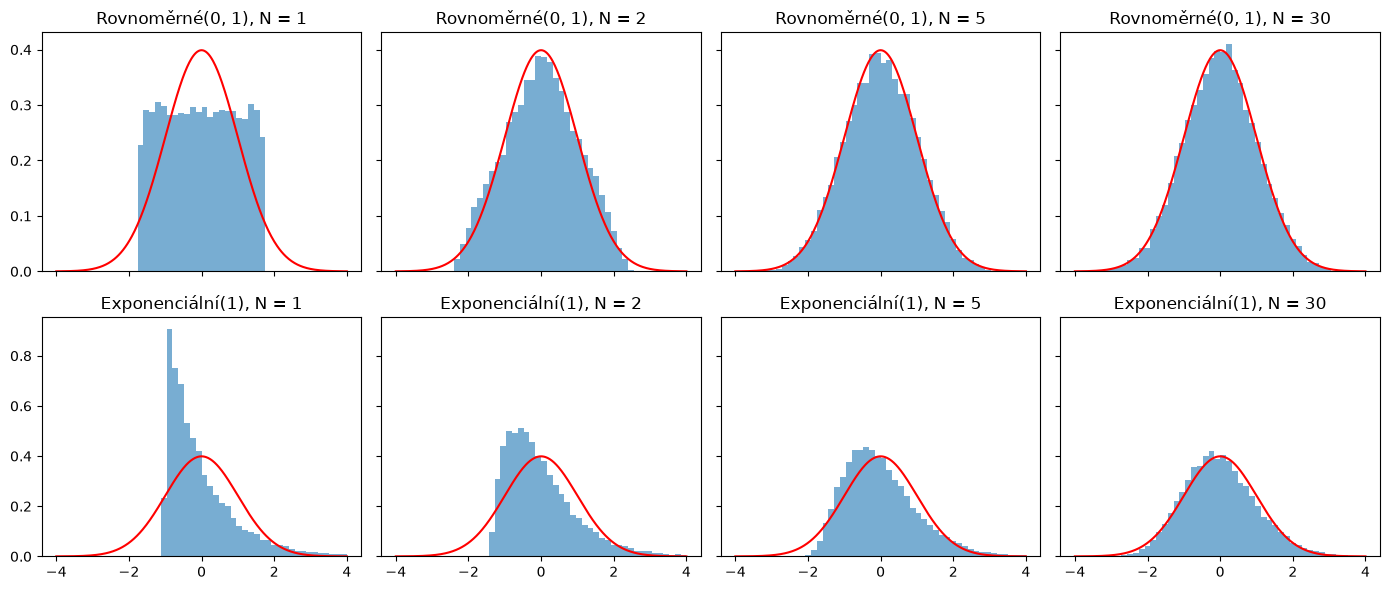

In [9]:
def standardizovane_prumery(gen, mu, sigma, N, behy=20_000):
    out = []
    for _ in range(behy):
        s = 0.0
        for _ in range(N):
            s += gen()
        out.append((s / N - mu) / (sigma / math.sqrt(N)))
    return out


zdroje_clv = [
    ("Rovnoměrné(0, 1)", random.random, 0.5, math.sqrt(1 / 12)),
    ("Exponenciální(1)", lambda: random.expovariate(1.0), 1.0, 1.0),
]
Ns = (1, 2, 5, 30)
grid = [i / 50 - 4 for i in range(401)]
pdf = [math.exp(-x * x / 2) / math.sqrt(2 * math.pi) for x in grid]

fig, axes = plt.subplots(len(zdroje_clv), len(Ns), figsize=(14, 6), sharex=True, sharey="row")
for r, (nazev, gen, mu, sigma) in enumerate(zdroje_clv):
    for c, N in enumerate(Ns):
        z = standardizovane_prumery(gen, mu, sigma, N)
        ax = axes[r][c]
        ax.hist(z, bins=50, range=(-4, 4), density=True, alpha=0.6)
        ax.plot(grid, pdf, "r")
        ax.set_title(f"{nazev}, N = {N}")
plt.tight_layout()
plt.show()

Červeně je hustota $N(0, 1)$. U rovnoměrného rozdělení stačí $N = 5$, u zešikmeného exponenciálního je potřeba víc: při $N = 30$ už zvon docela sedí, ale zešikmení je ještě vidět. **Čím je původní rozdělení méně symetrické, tím větší $N$ CLV potřebuje.**

### Proč u Monte Carla stačí „dvě sigmy"

Z CLV plyne, že s pravděpodobností $\approx 95\,\%$ platí $|\bar X_N - \mu| \le 1.96\,\sigma/\sqrt{N}$. Obecně $\delta = k_\alpha\,\sigma/\sqrt{N}$ a spolehlivost je $1 - \alpha$:

| Metoda | $k_\alpha$ pro 95 % | Platí |
|--------|---------------------|-------|
| CLV (normální) | $\approx 1.96 \approx 2$ | přibližně, pro velké $N$ |
| Čebyšev | $1/\sqrt{\alpha} \approx 4.47$ | vždy |

## 7. Interval spolehlivosti v praxi (Bernoulli)

Typická Monte Carlo úloha: odhadujeme pravděpodobnost $p$ (např. π nebo pravděpodobnost úpadku). Každý pokus je Bernoulliho: $X_i = 1$ s pravděpodobností $p$. Pak $\hat p = \bar X_N$ a $\sigma^2 = p(1-p) \le 1/4$.

Kolik pokusů potřebujeme, abychom $p$ určili s přesností $\delta = 0.01$ na 95 %? Pro nejhorší případ $\sigma = 1/2$:

- CLV: $N \ge (1.96 \cdot 0.5 / \delta)^2 \approx 1/\delta^2$
- Čebyšev: $N \ge 1 / (4\alpha\delta^2) = 5/\delta^2$

In [10]:
delta, alpha = 0.01, 0.05

N_clv = (1.96 * 0.5 / delta) ** 2
N_cheb = 1 / (4 * alpha * delta ** 2)
print(f"CLV:    N >= {N_clv:,.0f}".replace(",", " "))
print(f"Čebyšev: N >= {N_cheb:,.0f}  (to je {N_cheb / N_clv:.1f}x víc)".replace(",", " "))

CLV:    N >= 9 604
Čebyšev: N >= 50 000  (to je 5.2x víc)


Čebyšev je bezpečný, ale zhruba **5× dražší**. Funguje ale opravdu interval z CLV tak, jak slibuje? Zkusme to: pokus „odhadni $p$" zopakujeme 2000× a spočítáme, v kolika případech skutečné $p$ leželo v intervalu.

In [11]:
def pokryti(p, N, behy=2000, alpha=0.05):
    z = 1.96                        # CLV
    c = 1 / math.sqrt(alpha)        # Čebyšev
    ok_clv = ok_cheb = ok_cheb_worst = 0
    for _ in range(behy):
        ph = sum(random.random() < p for _ in range(N)) / N
        se = math.sqrt(ph * (1 - ph) / N)          # odhad sigma/sqrt(N)
        chyba = abs(ph - p)
        ok_clv += chyba <= z * se
        ok_cheb += chyba <= c * se
        ok_cheb_worst += chyba <= c * 0.5 / math.sqrt(N)   # sigma <= 1/2, žádný odhad
    print(f"p = {p}, N = {N}: pokrytí CLV {ok_clv / behy:.3f}, "
          f"Čebyšev (odhad sigma) {ok_cheb / behy:.3f}, Čebyšev (sigma = 1/2) {ok_cheb_worst / behy:.3f}")


pokryti(0.3, 400)
pokryti(0.01, 100)

p = 0.3, N = 400: pokrytí CLV 0.969, Čebyšev (odhad sigma) 1.000, Čebyšev (sigma = 1/2) 1.000
p = 0.01, N = 100: pokrytí CLV 0.637, Čebyšev (odhad sigma) 0.638, Čebyšev (sigma = 1/2) 1.000


Co z toho plyne:

- Pro $p = 0.3$ a $N = 400$ interval z CLV svých 95 % splní (naměřené pokrytí kolísá kolem 95–97 %, jde o náhodný pokus).
- Pro **malé $p$** (a málo pokusů) CLV selže: zhruba ve třetině běhů vyjde $\hat p = 0$, tedy $\hat\sigma = 0$ a interval nulové šířky, který skutečnou hodnotu nezachytí. Pravděpodobnost úpadku bývá právě malá, takže si na to dáme pozor v cvičení o pojišťovně.
- Čebyšev s nejhorším $\sigma = 1/2$ pokryje vždy, ale za cenu širokého intervalu.

## 8. Alternativa: NumPy

Všechno výše šlo napsat jen se standardní knihovnou. S NumPy je to kratší a rychlejší (celé pole vzorků najednou). NumPy se nainstaluje automaticky spolu s matplotlib; SciPy bude volitelná závislost (`uv sync --extra alt`) a objeví se až v dalších cvičeních.

In [12]:
try:
    import numpy as np

    rng = np.random.default_rng(1)
    xs = rng.integers(1, 7, size=100_000)                 # kostka, vektorově
    print(f"NumPy: E X = {xs.mean():.4f} +- {xs.std(ddof=1) / math.sqrt(xs.size):.4f}")

    # standardizované průměry z exponenciálního rozdělení, N = 30, bez cyklů
    z = (rng.exponential(1.0, size=(20_000, 30)).mean(axis=1) - 1.0) / (1.0 / math.sqrt(30))
    print(f"NumPy: Z_30 má průměr {z.mean():.3f} a rozptyl {z.var():.3f}  (čekáme 0 a 1)")
except ModuleNotFoundError:
    print("NumPy není nainstalované, spusťte:  uv sync")

NumPy: E X = 3.4974 +- 0.0054
NumPy: Z_30 má průměr -0.016 a rozptyl 1.001  (čekáme 0 a 1)


## Shrnutí

| Pojem | Co si pamatovat |
|-------|-----------------|
| $E X$, $D X$ | průměr a rozptyl; $D$ se sčítá jen u nezávislých veličin |
| Monte Carlo odhad | $\bar X_N \approx E X$, směrodatná chyba $\sigma/\sqrt{N}$ |
| Zákon velkých čísel | průměr konverguje k $\mu$ |
| Čebyšev | $P(\lvert\bar X - \mu\rvert \ge \delta) \le \sigma^2/(N\delta^2)$; vždy platí, ale hrubé ($k \approx 4.47$ pro 95 %) |
| CLV | $\bar X_N \approx N(\mu, \sigma/\sqrt N)$; přesnější ($k \approx 1.96$), ale jen pro velké $N$ |
| Bernoulli | $\sigma^2 = p(1-p) \le 1/4$; pro malé $p$ si na CLV dejte pozor |

### Zkuste si

1. Změňte `Ns` v grafu CLV na `(1, 10, 100)` a zdroj na kostku (`random.randint(1, 6)`, $\mu = 3.5$, $\sigma = \sqrt{35/12}$). Kdy začne vypadat jako zvon?
2. Spočítejte, kolik pokusů potřebujete pro $\delta = 0.001$ při spolehlivosti 99 % ($\alpha = 0.01$, CLV: $k \approx 2.576$). Jak se $N$ mění, když chcete desetkrát přesnější odhad?
3. V tabulce Čebyševovy nerovnosti přidejte $k = 1$ a $k = 1.2$. Co nerovnost říká pro $k = 1$ a proč je tato informace k ničemu?